**GPU checkup**

In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

I0000 00:00:1791647447.531897    1514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791647448.028049    1514 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791647450.181069    1514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
Num GPUs Available:  1


**Data Loading**

In [2]:
import os 
from pathlib import Path
root_dir = Path(os.getcwd()).parent
Data_dir = root_dir / "Data"
print("Data directory:", Data_dir)

Data directory: /mnt/d/Intel Image Classification/Intel-Image-Scene-Classification/Data


In [3]:
from pathlib import Path

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42
VALIDATION_SPLIT = 0.1

DATA_DIR = Path(Data_dir)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR}")

DATASET_ARGS = {
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "label_mode": "int",  # Four classes: buildings, forest, glacier, mountain
}


def load_dataset(subset: str):
    return tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=VALIDATION_SPLIT,
        subset=subset,
        seed=SEED,
        **DATASET_ARGS,
    )


train_ds = load_dataset("training")
val_ds = load_dataset("validation")
test_ds = load_dataset("validation")  # Using validation set as test set for this example

overlap = set(train_ds.file_paths) & set(val_ds.file_paths)
assert not overlap, f"train/validation leakage: {len(overlap)} shared images"

print(f"Dataset directory: {DATA_DIR}")
print(f"Train images: {len(train_ds.file_paths)}")
print(f"Validation images: {len(val_ds.file_paths)}")

class_names = train_ds.class_names
print("Classes:", class_names)

Found 8942 files belonging to 4 classes.
Using 8048 files for training.


I0000 00:00:1791647455.059696    1514 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 8942 files belonging to 4 classes.
Using 894 files for validation.
Found 8942 files belonging to 4 classes.
Using 894 files for validation.
Dataset directory: /mnt/d/Intel Image Classification/Intel-Image-Scene-Classification/Data
Train images: 8048
Validation images: 894
Classes: ['buildings', 'forest', 'glacier', 'mountain']


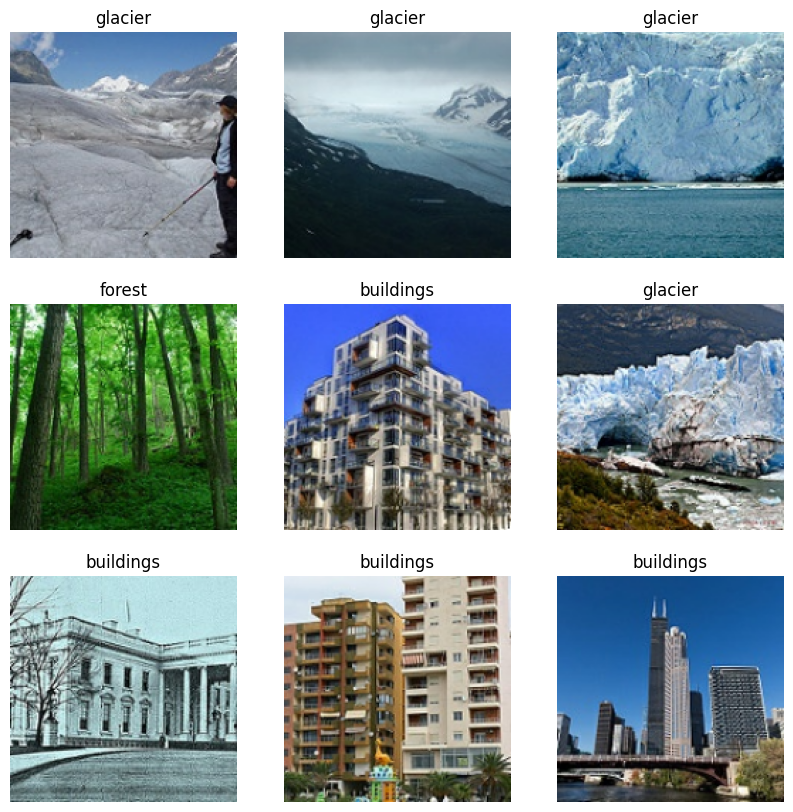

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1): #Grabs only the first batch 
                                       # from the dataset. If your batch size is 32, this single step pulls 32 images and 32 labels.
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

**Data Augmentation**

In [5]:
import tensorflow as tf
from tensorflow import keras # type: ignore
from tensorflow.keras import layers  # type: ignore
from tensorflow.keras.applications.vgg16 import preprocess_input

In [6]:
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
test_ds = test_ds.map(lambda x, y: (preprocess_input(x), y))
validation_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))

In [7]:
AutoTune = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AutoTune)
validation_ds = validation_ds.cache().prefetch(buffer_size=AutoTune)

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])


In [9]:
from tensorflow.keras.applications import VGG16
base_model = VGG16(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

In [10]:
input = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(input)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)  # Regularize with dropout
x = layers.Dense(128, activation='relu')(x)
output = layers.Dense(len(class_names), activation='softmax')(x)  # Assuming multi-class classification
model = tf.keras.Model(input, output)
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,868 (56.38 MB)

 Trainable params: 66,180 (258.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [11]:
EPOCHS = 50


history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    verbose = 2
    
)

Epoch 1/50


I0000 00:00:1791647464.013286    1932 cuda_dnn.cc:461] Loaded cuDNN version 91002
W0000 00:00:1791647465.153175    1932 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 3.04GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1791647490.433734    1930 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.98GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


252/252 - 34s - 134ms/step - accuracy: 0.9077 - loss: 0.3553 - val_accuracy: 0.9497 - val_loss: 0.1566
Epoch 2/50
252/252 - 22s - 87ms/step - accuracy: 0.9351 - loss: 0.1844 - val_accuracy: 0.9508 - val_loss: 0.1509
Epoch 3/50
252/252 - 22s - 87ms/step - accuracy: 0.9433 - loss: 0.1560 - val_accuracy: 0.9474 - val_loss: 0.1541
Epoch 4/50
252/252 - 22s - 87ms/step - accuracy: 0.9483 - loss: 0.1375 - val_accuracy: 0.9530 - val_loss: 0.1561
Epoch 5/50
252/252 - 22s - 87ms/step - accuracy: 0.9481 - loss: 0.1403 - val_accuracy: 0.9564 - val_loss: 0.1396
Epoch 6/50
252/252 - 22s - 87ms/step - accuracy: 0.9469 - loss: 0.1354 - val_accuracy: 0.9497 - val_loss: 0.1534
Epoch 7/50
252/252 - 22s - 87ms/step - accuracy: 0.9472 - loss: 0.1251 - val_accuracy: 0.9508 - val_loss: 0.1511
Epoch 8/50
252/252 - 22s - 88ms/step - accuracy: 0.9486 - loss: 0.1285 - val_accuracy: 0.9575 - val_loss: 0.1403
Epoch 9/50
252/252 - 22s - 88ms/step - accuracy: 0.9519 - loss: 0.1230 - val_accuracy: 0.9497 - val_loss: 